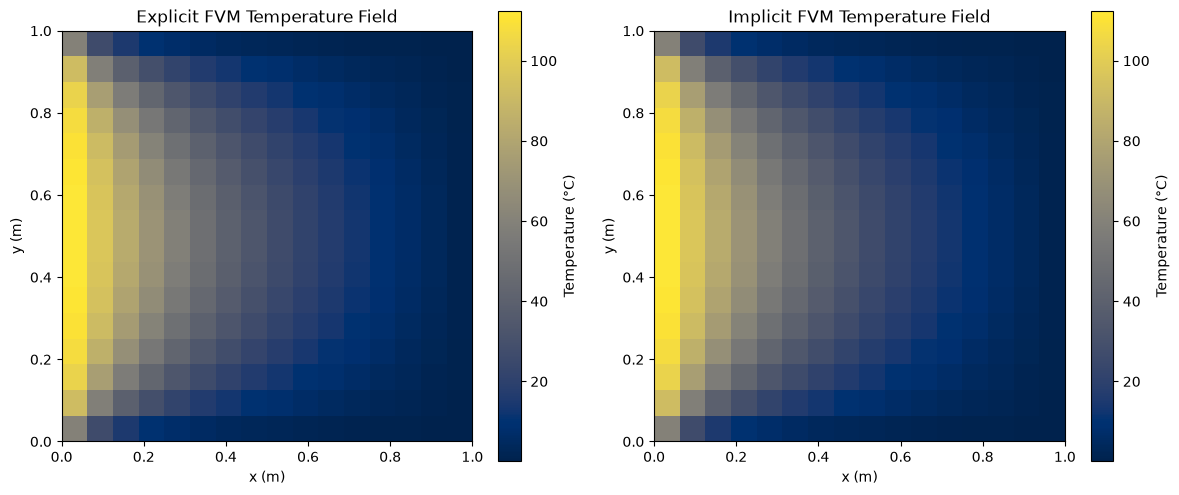

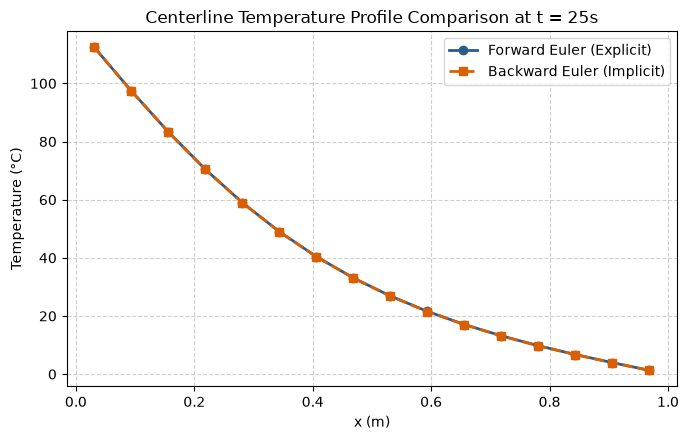

In [4]:
"""
  CFD & HT Lab - Experiment 6
  Topic: 2D Transient Heat Conduction (Cell-Centred FVM)
  
  Student Name : Dev Pateliya
  Roll Number  : 23BME081
  Semester     : 7th Semester (B.Tech Mechanical Engineering)
"""

import numpy as np
import matplotlib.pyplot as plt

Lx, Ly = 1.0, 1.0
Nx, Ny = 16, 16

dx = Lx / Nx
dy = Ly / Ny
alpha = 0.015

T_left = 120.0
T_right = 0.0
T_bottom = 0.0
T_top = 0.0

t_end = 25.0

dt_exp = 0.3 / (alpha * (1.0 / dx**2 + 1.0 / dy**2))
steps_exp = int(np.ceil(t_end / dt_exp))
dt_exp = t_end / steps_exp
rx = alpha * dt_exp / dx**2
ry = alpha * dt_exp / dy**2

T_exp = np.zeros((Ny, Nx))

for n in range(steps_exp):
    old = T_exp.copy()
    new = old.copy()
    
    for j in range(Ny):
        for i in range(Nx):
            P = old[j, i]
            
            west = 2.0 * (T_left - P) if i == 0 else old[j, i - 1] - P
            east = 2.0 * (T_right - P) if i == Nx - 1 else old[j, i + 1] - P
            south = 2.0 * (T_bottom - P) if j == 0 else old[j - 1, i] - P
            north = 2.0 * (T_top - P) if j == Ny - 1 else old[j + 1, i] - P
            
            new[j, i] = P + rx * (east + west) + ry * (north + south)
            
    T_exp = new.copy()

dt_imp = 1.0
steps_imp = int(np.ceil(t_end / dt_imp))
dt_imp = t_end / steps_imp
rx_imp = alpha * dt_imp / dx**2
ry_imp = alpha * dt_imp / dy**2

M = Nx * Ny
A = np.zeros((M, M))
source = np.zeros(M)

for j in range(Ny):
    for i in range(Nx):
        p = j * Nx + i
        aP = 1.0
        
        if i == 0:
            aP += 2.0 * rx_imp
            source[p] += 2.0 * rx_imp * T_left
        else:
            aP += rx_imp
            A[p, p - 1] = -rx_imp
            
        if i == Nx - 1:
            aP += 2.0 * rx_imp
            source[p] += 2.0 * rx_imp * T_right
        else:
            aP += rx_imp
            A[p, p + 1] = -rx_imp
            
        if j == 0:
            aP += 2.0 * ry_imp
            source[p] += 2.0 * ry_imp * T_bottom
        else:
            aP += ry_imp
            A[p, p - Nx] = -ry_imp
            
        if j == Ny - 1:
            aP += 2.0 * ry_imp
            source[p] += 2.0 * ry_imp * T_top
        else:
            aP += ry_imp
            A[p, p + Nx] = -ry_imp
            
        A[p, p] = aP

T_imp = np.zeros((Ny, Nx))

for n in range(steps_imp):
    b = T_imp.ravel() + source
    T_imp = np.linalg.solve(A, b).reshape((Ny, Nx))

# --- Side-by-Side Contour Plots ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

im1 = axes[0].imshow(T_exp, origin="lower", extent=[0, Lx, 0, Ly], aspect="equal", cmap="cividis")
axes[0].set_xlabel("x (m)")
axes[0].set_ylabel("y (m)")
axes[0].set_title("Explicit FVM Temperature Field")
fig.colorbar(im1, ax=axes[0], label="Temperature (°C)")

im2 = axes[1].imshow(T_imp, origin="lower", extent=[0, Lx, 0, Ly], aspect="equal", cmap="cividis")
axes[1].set_xlabel("x (m)")
axes[1].set_ylabel("y (m)")
axes[1].set_title("Implicit FVM Temperature Field")
fig.colorbar(im2, ax=axes[1], label="Temperature (°C)")

plt.tight_layout()
plt.show()

# --- Centerline Comparison Plot ---
x_centres = np.linspace(dx / 2.0, Lx - dx / 2.0, Nx)
centerline_exp = (T_exp[Ny // 2 - 1, :] + T_exp[Ny // 2, :]) / 2.0
centerline_imp = (T_imp[Ny // 2 - 1, :] + T_imp[Ny // 2, :]) / 2.0

plt.figure(figsize=(7, 4.5))
plt.plot(x_centres, centerline_exp, 'o-', color='#2b5c8f', linewidth=2, label='Forward Euler (Explicit)')
plt.plot(x_centres, centerline_imp, 's--', color='#d95f02', linewidth=2, label='Backward Euler (Implicit)')
plt.xlabel("x (m)")
plt.ylabel("Temperature (°C)")
plt.title("Centerline Temperature Profile Comparison at t = 25s")
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()